<a href="https://colab.research.google.com/github/gonzagax00/Intelig-ncia-Artificial/blob/main/FishMorphDB_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inteligência Artificial — FishMorphDB

Classificação de peixes a partir de traços morfológicos usando **SVM** com **Grid Search** e **validação cruzada**.

1. Importação do dataset (biblioteca do Kaggle)
2. Análise e limpeza dos dados (nulos, duplicados, tipos)
3. Distribuição das categorias e visualização
4. Divisão treino/teste e cross validation
5. Grid Search — 4 valores para cada hiperparâmetro (`kernel`, `C`, `gamma`)
6. Melhor modelo, parâmetros e acurácia
7. Acurácia no teste e matriz de confusão

## 1. Importação do dataset

In [ ]:
!pip install -q kagglehub

In [ ]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [ ]:
# Identificador do dataset no Kaggle: é o trecho da URL depois de /datasets/
# Ex.: https://www.kaggle.com/datasets/usuario/nome-do-dataset  ->  "usuario/nome-do-dataset"
KAGGLE_DATASET = "menegidio/fishmorph-dataset"   # <-- TROQUE pelo identificador real

path = kagglehub.dataset_download(KAGGLE_DATASET)
print("Arquivos baixados em:", path)
for f in glob.glob(os.path.join(path, "**", "*"), recursive=True):
    if os.path.isfile(f):
        print(f" - {os.path.relpath(f, path)}  ({os.path.getsize(f)/1024:.1f} KB)")

Using Colab cache for faster access to the 'fishmorph-dataset' dataset.
Arquivos baixados em: /kaggle/input/fishmorph-dataset
 - FISHMORPH_Order_Dataset.csv  (1011.0 KB)
 - FISHMORPH_Family_Dataset.csv  (992.5 KB)


In [ ]:
# Carrega o maior CSV da pasta (o arquivo de dados; o 'Readme' é bem menor)
csvs = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
assert csvs, "Nenhum CSV encontrado no dataset."
csv_path = max(csvs, key=os.path.getsize)
print("Lendo:", csv_path)

def ler_csv(caminho):
    # sep=None detecta o separador (',' ou ';') automaticamente
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(caminho, sep=None, engine="python", encoding=enc)
        except UnicodeDecodeError:
            continue
    raise

df = ler_csv(csv_path)
df.columns = df.columns.str.strip()
print("Formato:", df.shape)
df.head()

Lendo: /kaggle/input/fishmorph-dataset/FISHMORPH_Order_Dataset.csv
Formato: (8342, 11)


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Order
0,130.0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991,Cypriniformes
1,11.5,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592,Perciformes
2,6.6,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580,Cypriniformes
3,10.9,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062,Cypriniformes
4,18.9,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906,Cypriniformes


## 2. Análise e limpeza dos dados

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8342 entries, 0 to 8341
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MBl     8342 non-null   float64
 1   BEl     8342 non-null   float64
 2   VEp     8342 non-null   float64
 3   REs     8342 non-null   float64
 4   OGp     8342 non-null   float64
 5   RMl     8342 non-null   float64
 6   BLs     8342 non-null   float64
 7   PFv     8342 non-null   float64
 8   PFs     8342 non-null   float64
 9   CPt     8342 non-null   float64
 10  Order   8342 non-null   object 
dtypes: float64(10), object(1)
memory usage: 717.0+ KB


In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
MBl,8342.0,NaN,NaN,NaN,22.004517,33.612007,1.2,7.0,12.6,24.5,800.0
BEl,8342.0,NaN,NaN,NaN,4.452438,2.338235,1.033084,3.139102,4.038851,5.002621,43.728161
VEp,8342.0,NaN,NaN,NaN,0.549087,0.094883,0.159248,0.487993,0.546213,0.605125,1.0
REs,8342.0,NaN,NaN,NaN,0.391665,0.132814,0.0,0.293205,0.389429,0.486221,1.026667
OGp,8342.0,NaN,NaN,NaN,0.381768,0.194352,0.0,0.278014,0.406904,0.516001,1.026316
RMl,8342.0,NaN,NaN,NaN,0.399786,0.302658,0.0,0.257999,0.361436,0.490671,7.060344
BLs,8342.0,NaN,NaN,NaN,0.571818,0.117486,0.224525,0.490052,0.564739,0.648039,1.230105
PFv,8342.0,NaN,NaN,NaN,0.285316,0.155629,0.0,0.193134,0.275039,0.368876,0.857097
PFs,8342.0,NaN,NaN,NaN,0.189343,0.056109,0.0,0.157972,0.183497,0.215031,0.511113
CPt,8342.0,NaN,NaN,NaN,2.560795,1.016659,0.0,1.999744,2.436329,2.919818,15.452061


In [ ]:
print("Valores nulos por coluna:")
print(df.isnull().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())

Valores nulos por coluna:
MBl      0
BEl      0
VEp      0
REs      0
OGp      0
RMl      0
BLs      0
PFv      0
PFs      0
CPt      0
Order    0
dtype: int64

Linhas duplicadas: 1


### Definição do alvo e das features

- **Alvo (`TARGET`)**: a categoria taxonômica do peixe (por padrão, a **ordem**).
- **Features**: os traços morfológicos numéricos. Colunas de identificação (códigos, nomes, referências) são descartadas.

Se o nome das colunas do seu arquivo for diferente, ajuste `TARGET` manualmente.

In [ ]:
# Colunas de texto que na verdade são numéricas (ex.: decimal com vírgula) -> converte
for col in df.select_dtypes(include="object").columns:
    conv = pd.to_numeric(df[col].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    if conv.notna().sum() >= 0.9 * df[col].notna().sum() and conv.notna().sum() > 0:
        df[col] = conv

# Alvo: primeira coluna candidata que existir
candidatas = ["Order", "order", "Ordem", "Family", "family", "Familia", "Suborder", "Class", "class", "Species", "species"]
TARGET = next((c for c in candidatas if c in df.columns), None)
assert TARGET is not None, f"Defina TARGET manualmente. Colunas: {list(df.columns)}"

# Features: numéricas, exceto identificadores
ids = ("code", "id", "index", "unnamed")
FEATURES = [c for c in df.select_dtypes(include="number").columns
            if c != TARGET and not any(k in c.lower() for k in ids)]

print("Alvo    :", TARGET)
print("Features:", FEATURES)

Alvo    : Order
Features: ['MBl', 'BEl', 'VEp', 'REs', 'OGp', 'RMl', 'BLs', 'PFv', 'PFs', 'CPt']


In [ ]:
dados = df[FEATURES + [TARGET]].copy()
antes = len(dados)

dados = dados.dropna()                 # remove linhas com valores nulos
dados = dados.drop_duplicates()        # remove duplicadas
dados[TARGET] = dados[TARGET].astype(str).str.strip()

print(f"Linhas antes: {antes} | depois da limpeza: {len(dados)} | removidas: {antes - len(dados)}")
print("Nulos restantes:", dados.isnull().sum().sum())

Linhas antes: 8342 | depois da limpeza: 8341 | removidas: 1
Nulos restantes: 0


### Classes com poucas amostras

Há categorias com pouquíssimos exemplos, o que inviabiliza a divisão estratificada e a validação cruzada (cada fold precisa ter exemplos de todas as classes). Mantemos apenas as classes com pelo menos `MIN_AMOSTRAS` registros.

In [ ]:
MIN_AMOSTRAS = 100

contagem = dados[TARGET].value_counts()
classes_ok = contagem[contagem >= MIN_AMOSTRAS].index
dados = dados[dados[TARGET].isin(classes_ok)].reset_index(drop=True)

print(f"Classes mantidas: {len(classes_ok)} de {len(contagem)}")
print("Formato final:", dados.shape)

Classes mantidas: 8 de 32
Formato final: (7755, 11)


## 3. Distribuição das categorias e visualização dos dados

                     qtd      %
Order                          
Cypriniformes       1933  24.93
Perciformes         1826  23.55
Siluriformes        1800  23.21
Characiformes       1281  16.52
Cyprinodontiformes   554   7.14
Osteoglossiformes    156   2.01
Clupeiformes         104   1.34
Gymnotiformes        101   1.30


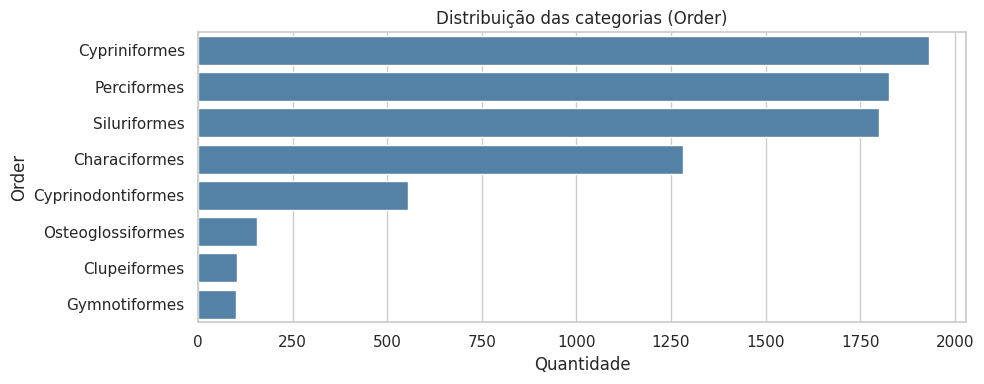

In [ ]:
dist = dados[TARGET].value_counts()
print(pd.DataFrame({"qtd": dist, "%": (dist / len(dados) * 100).round(2)}))

plt.figure(figsize=(10, max(4, 0.4 * len(dist))))
sns.barplot(x=dist.values, y=dist.index, color="steelblue")
plt.title(f"Distribuição das categorias ({TARGET})")
plt.xlabel("Quantidade"); plt.ylabel(TARGET)
plt.tight_layout(); plt.show()

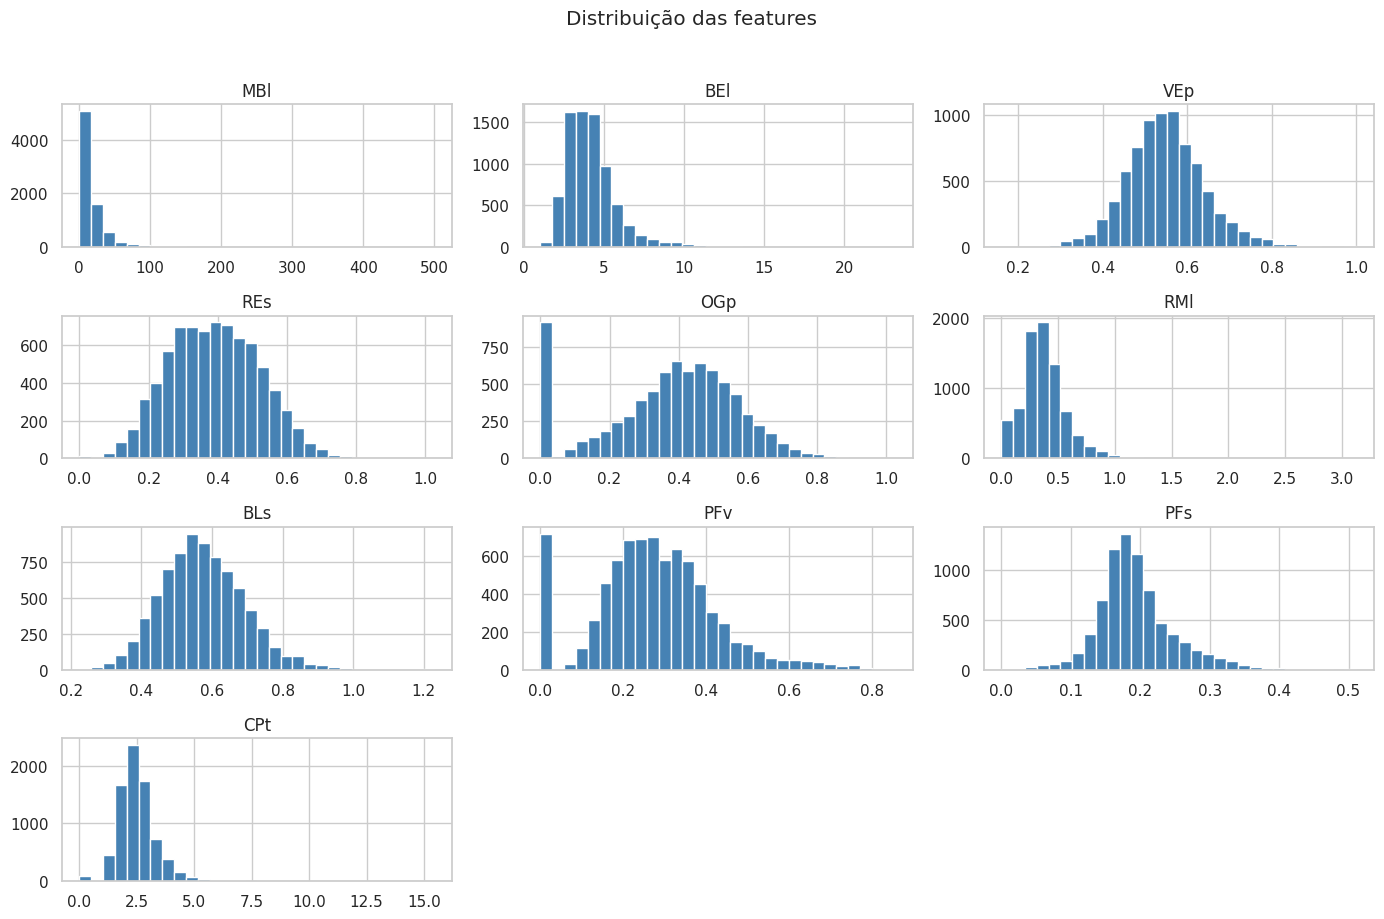

In [ ]:
dados[FEATURES].hist(bins=30, figsize=(14, 9), color="steelblue", edgecolor="white")
plt.suptitle("Distribuição das features", y=1.02)
plt.tight_layout(); plt.show()

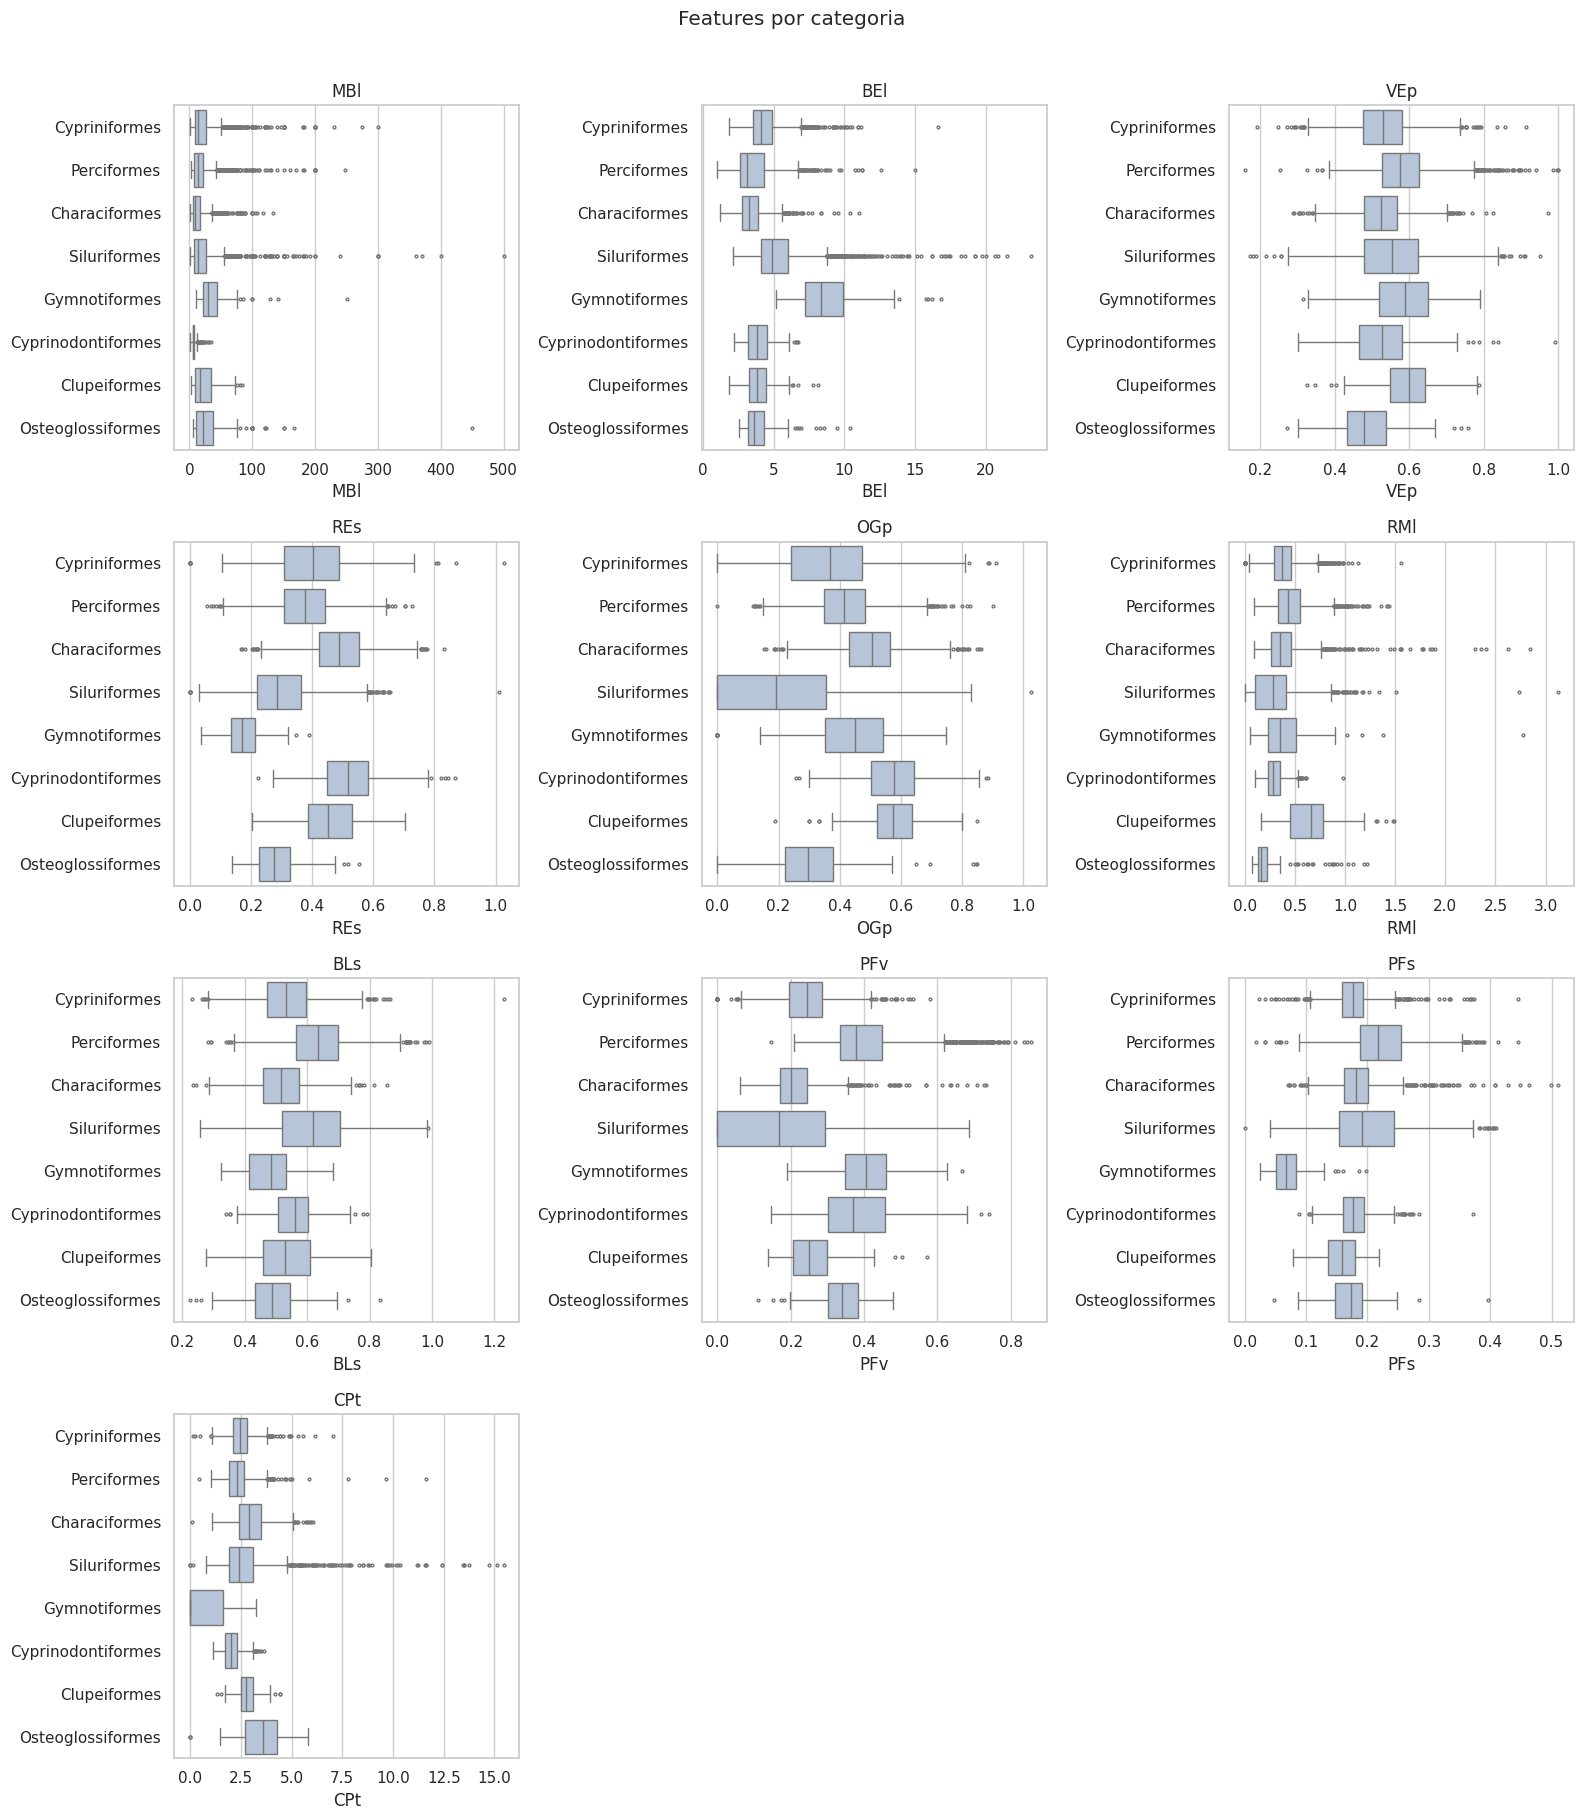

In [ ]:
n = len(FEATURES); ncols = 3; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, FEATURES):
    sns.boxplot(data=dados, x=col, y=TARGET, ax=ax, color="lightsteelblue", fliersize=2)
    ax.set_title(col); ax.set_ylabel("")
for ax in axes[n:]:
    ax.axis("off")
plt.suptitle("Features por categoria", y=1.01)
plt.tight_layout(); plt.show()

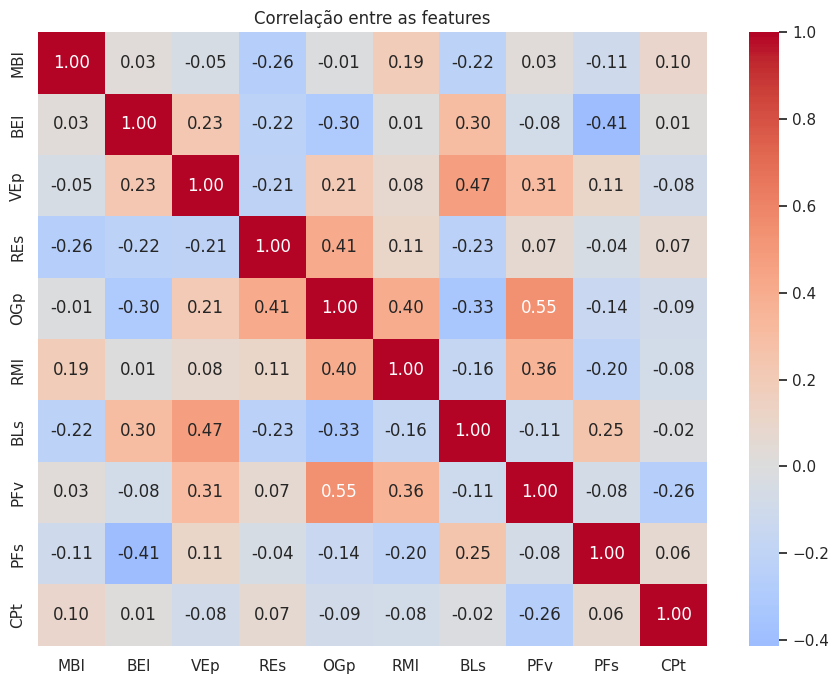

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(dados[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre as features")
plt.tight_layout(); plt.show()

## 4. Divisão treino/teste e cross validation

In [ ]:
X = dados[FEATURES]
y = dados[TARGET]

# 80% treino / 20% teste, estratificado para manter a proporção das classes
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)

Treino: (6204, 10) | Teste: (1551, 10)


In [ ]:
# O SVM é sensível à escala: o StandardScaler fica dentro do Pipeline para ser
# ajustado apenas nos folds de treino (evita vazamento de dados).
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(random_state=RANDOM_STATE)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
print("Acurácia por fold (SVM padrão):", scores.round(4))
print(f"Média: {scores.mean():.4f} | Desvio padrão: {scores.std():.4f}")

Acurácia por fold (SVM padrão): [0.8066 0.8131 0.8098 0.805  0.8137]
Média: 0.8096 | Desvio padrão: 0.0034


## 5. Grid Search

4 valores para cada hiperparâmetro → 4 × 4 × 4 = **64 combinações**, cada uma avaliada com 5 folds (**320 treinos**).

Observação: `gamma` não tem efeito no kernel `linear`; o Grid Search testa as combinações mesmo assim. Pode levar alguns minutos.

In [43]:
param_grid = {
    "svc__kernel": ["linear", "poly", "rbf", "sigmoid"],
    "svc__C":      [0.1, 1, 10, 100],
    "svc__gamma":  [0.0001, 0.001, 0.01, 0.1],
}

# limite de iterações + mais cache de kernel
pipe.set_params(svc__max_iter=20000, svc__cache_size=1000)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2,
    return_train_score=False,
)
grid.fit(X_train, y_train)

Fitting 3 folds for each of 64 candidates, totalling 192 fits


GridSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svc',
                                        SVC(cache_size=1000, max_iter=20000,
                                            random_state=42))]),
             n_jobs=-1,
             param_grid={'svc__C': [0.1, 1, 10, 100],
                         'svc__gamma': [0.0001, 0.001, 0.01, 0.1],
                         'svc__kernel': ['linear', 'poly', 'rbf', 'sigmoid']},
             scoring='accuracy', verbose=2)

## 6. Melhor modelo, parâmetros e acurácia

In [44]:
print("Modelo             :", type(grid.best_estimator_.named_steps["svc"]).__name__, "(Support Vector Classifier)")
print("Melhores parâmetros:", {k.replace("svc__", ""): v for k, v in grid.best_params_.items()})
print(f"Acurácia média na validação cruzada: {grid.best_score_:.4f}")
print("\nTodos os parâmetros do modelo:")
print(grid.best_estimator_.named_steps["svc"].get_params())

Modelo             : SVC (Support Vector Classifier)
Melhores parâmetros: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Acurácia média na validação cruzada: 0.8179

Todos os parâmetros do modelo:
{'C': 10, 'break_ties': False, 'cache_size': 1000, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 0.1, 'kernel': 'rbf', 'max_iter': 20000, 'probability': False, 'random_state': 42, 'shrinking': True, 'tol': 0.001, 'verbose': False}


In [46]:
res = pd.DataFrame(grid.cv_results_)
cols = ["param_svc__kernel", "param_svc__C", "param_svc__gamma",
        "mean_test_score", "std_test_score", "rank_test_score"]
res[cols].sort_values("rank_test_score").head(10).reset_index(drop=True)

,param_svc__kernel,param_svc__C,param_svc__gamma,mean_test_score,std_test_score,rank_test_score
0,rbf,10.0,0.100,0.817859,0.003753,1
1,rbf,1.0,0.100,0.805609,0.006524,2
2,rbf,100.0,0.010,0.803191,0.005598,3
3,rbf,10.0,0.010,0.790941,0.008017,4
4,rbf,100.0,0.100,0.790619,0.003553,5
5,poly,10.0,0.100,0.769504,0.003358,6
6,rbf,100.0,0.001,0.764507,0.003889,7
7,poly,100.0,0.100,0.759026,0.019978,8
8,rbf,1.0,0.010,0.752740,0.006563,9
9,rbf,0.1,0.100,0.745164,0.005816,10


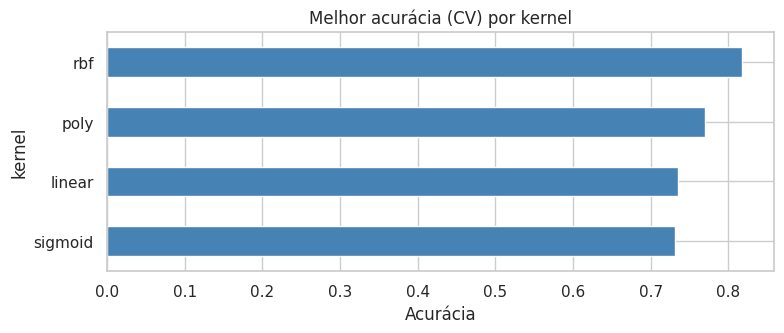

In [47]:
# Melhor acurácia de validação por kernel
melhor_kernel = res.groupby("param_svc__kernel")["mean_test_score"].max().sort_values()
melhor_kernel.plot(kind="barh", color="steelblue", figsize=(8, 3.5))
plt.title("Melhor acurácia (CV) por kernel"); plt.xlabel("Acurácia"); plt.ylabel("kernel")
plt.tight_layout(); plt.show()

## 7. Acurácia no teste e matriz de confusão

In [48]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Acurácia no conjunto de teste: {acc:.4f} ({acc*100:.2f}%)\n")
print(classification_report(y_test, y_pred, zero_division=0))

Acurácia no conjunto de teste: 0.8143 (81.43%)

                    precision    recall  f1-score   support

     Characiformes       0.79      0.72      0.75       256
      Clupeiformes       0.44      0.33      0.38        21
     Cypriniformes       0.71      0.80      0.75       387
Cyprinodontiformes       0.84      0.87      0.86       111
     Gymnotiformes       0.86      0.95      0.90        20
 Osteoglossiformes       0.93      0.87      0.90        31
       Perciformes       0.91      0.94      0.93       365
      Siluriformes       0.85      0.77      0.81       360

          accuracy                           0.81      1551
         macro avg       0.79      0.78      0.79      1551
      weighted avg       0.82      0.81      0.81      1551



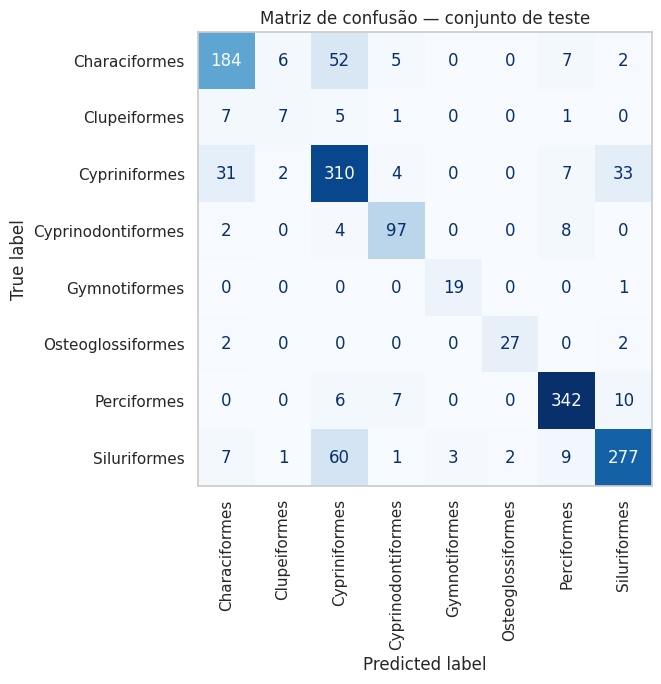

In [49]:
labels = best_model.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)

tam = max(7, 0.7 * len(labels))
fig, ax = plt.subplots(figsize=(tam, tam))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", xticks_rotation=90, colorbar=False)
ax.set_title("Matriz de confusão — conjunto de teste")
ax.grid(False)
plt.tight_layout(); plt.show()

## Resumo

In [50]:
p = grid.best_params_
print("Modelo: SVM (SVC)")
print(f"Parâmetros: kernel={p['svc__kernel']}, C={p['svc__C']}, gamma={p['svc__gamma']}")
print(f"Acurácia (cross validation, 5 folds): {grid.best_score_:.4f}")
print(f"Acurácia (teste): {acc:.4f}")

Modelo: SVM (SVC)
Parâmetros: kernel=rbf, C=10, gamma=0.1
Acurácia (cross validation, 5 folds): 0.8179
Acurácia (teste): 0.8143
